In [9]:
import torch
import matplotlib.pyplot as plt
from results.inception_experiments import results, experiments, final_test_result

In [ ]:
run = experiments[0]
history = run["epoch_history"]

epochs = [row["epoch"] for row in history]
val_accuracy = [row["validation_accuracy_pct"] for row in history]

run

{'experiment_id': 'adamw_crop_flip',
 'status': 'Retained: user confirms run preceded leaking loader change; saved source has historical naming/argument mismatches',
 'optimizer': 'AdamW',
 'weight_decay': 0.0001,
 'batchnorm': False,
 'trainable_parameters': 818500,
 'augmentation': 'crop + flip; user clarified historical run',
 'selected_result': {'epoch': 19,
  'training_accuracy_pct': 74.15,
  'validation_accuracy_pct': 57.08,
  'validation_loss': 1.8555},
 'printed_checkpoint': 'best_inception_cifar100_ep20.pt',
 'epoch_history': [{'epoch': 1,
   'train_loss': 3.9006,
   'validation_loss': 3.5059,
   'validation_accuracy_pct': 15.62,
   'epoch_seconds': 96.2},
  {'epoch': 2,
   'train_loss': 3.2595,
   'validation_loss': 2.9903,
   'validation_accuracy_pct': 24.8,
   'epoch_seconds': 95.6},
  {'epoch': 3,
   'train_loss': 2.7533,
   'validation_loss': 2.7236,
   'validation_accuracy_pct': 31.92,
   'epoch_seconds': 96.4},
  {'epoch': 4,
   'train_loss': 2.4242,
   'validation_loss

In [23]:
names = []
accuracies = []

for exp in experiments:
    names.append(exp["experiment_id"])
    accuracies.append(exp["selected_result"]["validation_accuracy_pct"])
    
names , accuracies

(['adamw_crop_flip',
  'adamw_flip_baseline',
  'adam_crop_corrected',
  'adam_batchnorm_crop_corrected',
  'adamw_batchnorm_crop'],
 [57.08, 57.08, 56.66, 68.16, 68.98])

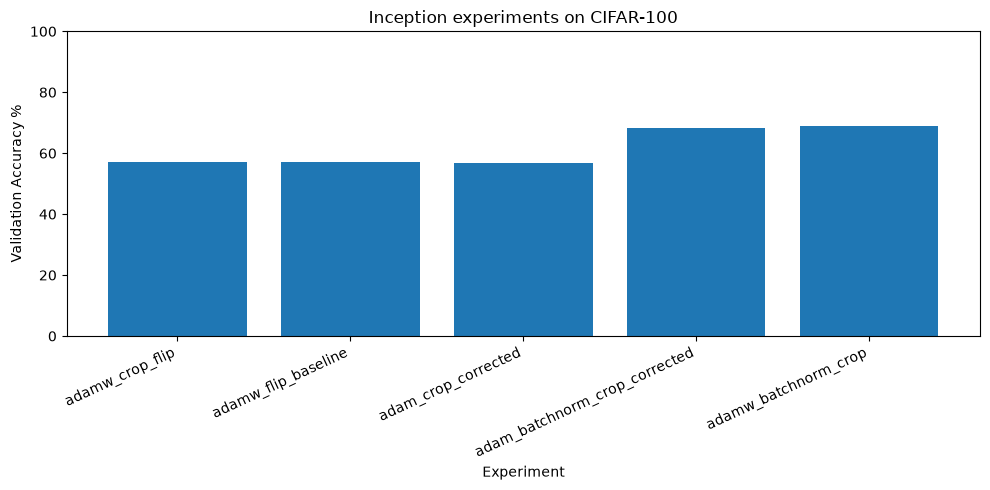

In [25]:
fig, ax = plt.subplots(figsize=(10,5))

ax.bar(names, accuracies)

ax.set_xlabel("Experiment")
ax.set_ylabel("Validation Accuracy %")

ax.set_title("Inception experiments on CIFAR-100")

ax.set_ylim(0, 100)

plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

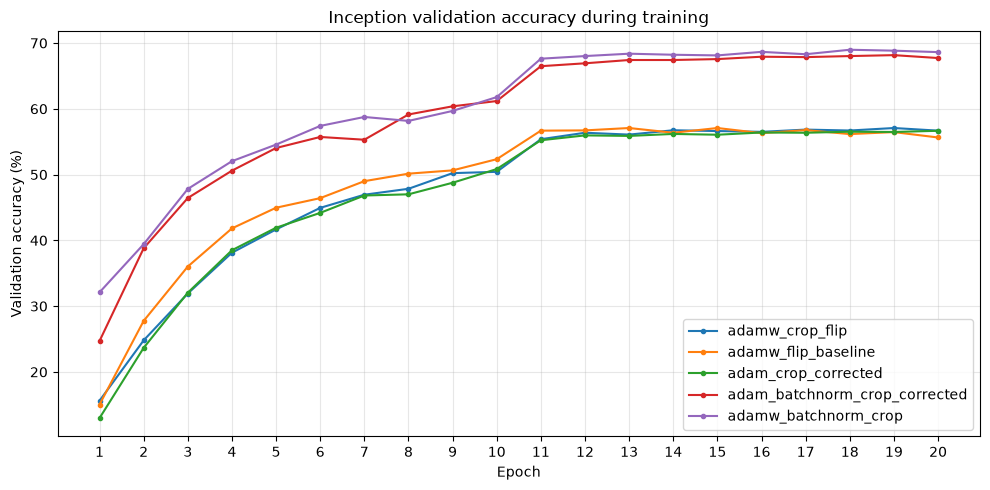

In [28]:
fig, ax = plt.subplots(figsize=(10, 5))

for experiment in experiments:
    # AdamW + BatchNorm stores its history inside "details".
    history = experiment.get("epoch_history")
    if history is None:
        history = experiment["details"]["epoch_history"]

    epochs = [row["epoch"] for row in history]
    accuracy = [
        row["validation_accuracy_pct"] for row in history
    ]

    ax.plot(
        epochs,
        accuracy,
        label=experiment["experiment_id"],
        marker="o",
        markersize=3,
    )

ax.set_xlabel("Epoch")
ax.set_ylabel("Validation accuracy (%)")
ax.set_title("Inception validation accuracy during training")
ax.set_xticks(range(1, 21))
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

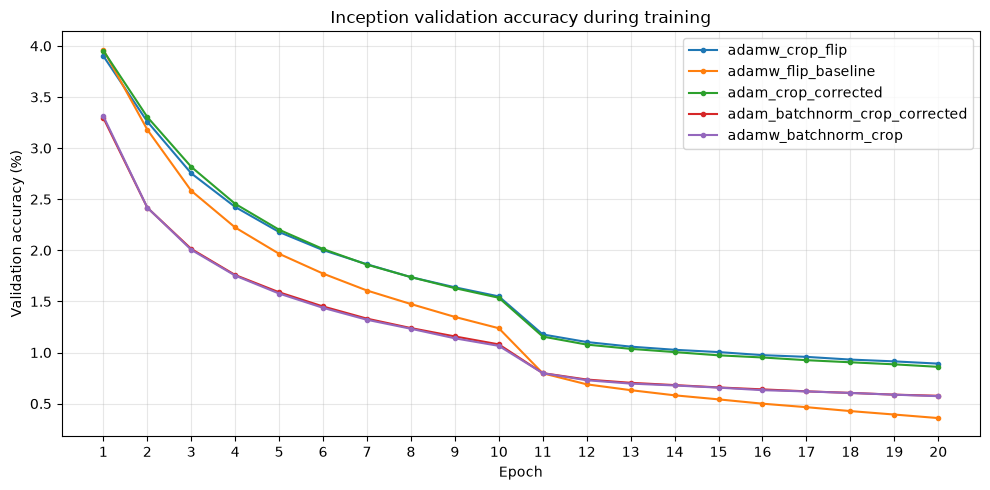

In [30]:
fig, ax = plt.subplots(figsize=(10, 5))

for experiment in experiments:
    # AdamW + BatchNorm stores its history inside "details".
    history = experiment.get("epoch_history")
    if history is None:
        history = experiment["details"]["epoch_history"]

    epochs = [row["epoch"] for row in history]
    error = [
        row["train_loss"] for row in history
    ]

    ax.plot(
        epochs,
        error,
        label=experiment["experiment_id"],
        marker="o",
        markersize=3,
    )

ax.set_xlabel("Epoch")
ax.set_ylabel("Validation accuracy (%)")
ax.set_title("Inception validation accuracy during training")
ax.set_xticks(range(1, 21))
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

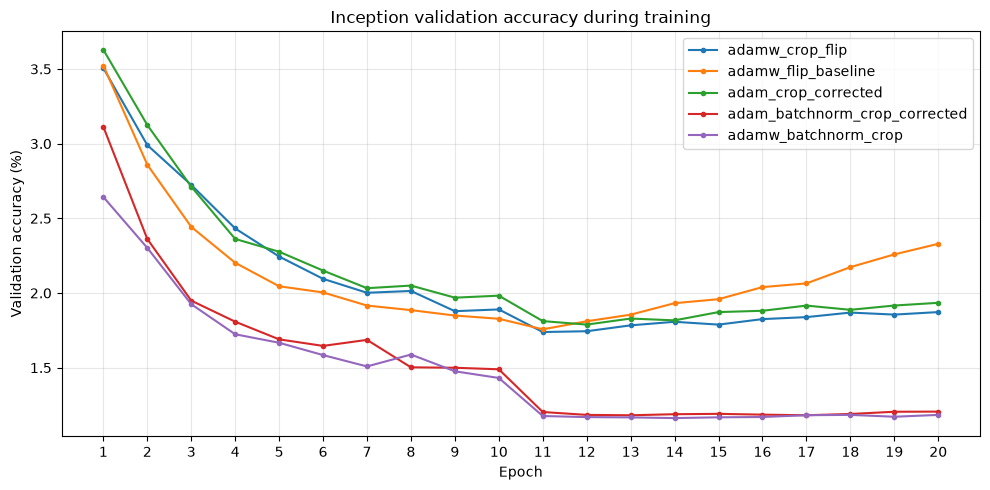

In [31]:
fig, ax = plt.subplots(figsize=(10, 5))

for experiment in experiments:
    # AdamW + BatchNorm stores its history inside "details".
    history = experiment.get("epoch_history")
    if history is None:
        history = experiment["details"]["epoch_history"]

    epochs = [row["epoch"] for row in history]
    error = [
        row["validation_loss"] for row in history
    ]

    ax.plot(
        epochs,
        error,
        label=experiment["experiment_id"],
        marker="o",
        markersize=3,
    )

ax.set_xlabel("Epoch")
ax.set_ylabel("Validation accuracy (%)")
ax.set_title("Inception validation accuracy during training")
ax.set_xticks(range(1, 21))
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()